In [1]:
# Inventory Forecasting
## Objective: Forecast future demand and identify potential inventory risks before they impact store operations.

## Business Value:

## Improve inventory availability
## Reduce stockouts
## Optimize replenishment planning
## Improve working capital efficiency

In [2]:
# Load Data

import pandas as pd

df = pd.read_csv("retail_store_inventory.csv")

df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [3]:
# Prepare Date Field

df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values("Date")

In [4]:
# Aggregate Daily Demand

daily_sales = (
    df.groupby("Date")["Units Sold"]
    .sum()
    .reset_index()
)

daily_sales.head()

,Date,Units Sold
0,2022-01-01,14484
1,2022-01-02,13415
2,2022-01-03,13681
3,2022-01-04,14084
4,2022-01-05,12572


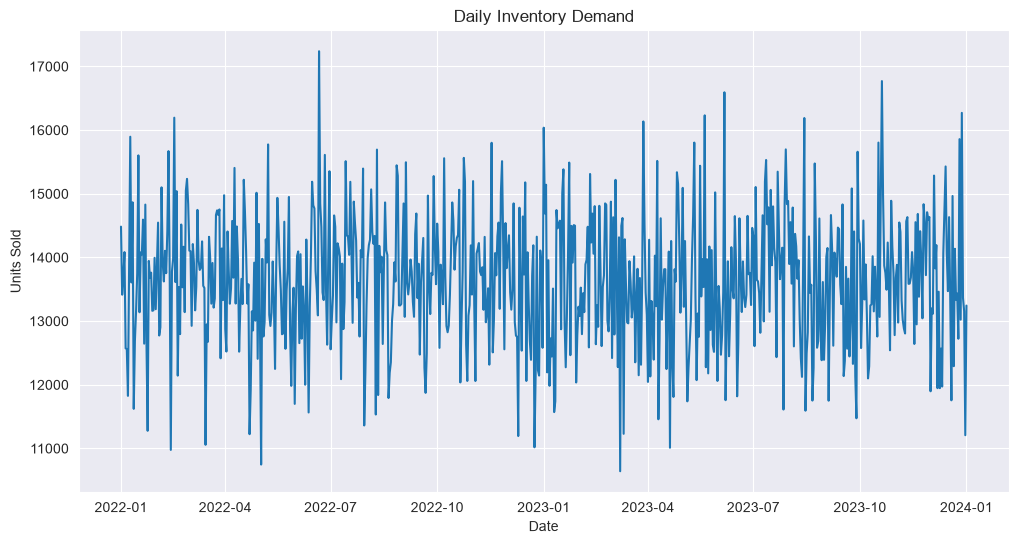

In [5]:
# Visualize Demand Trend

import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.plot(
    daily_sales["Date"],
    daily_sales["Units Sold"]
)

plt.title("Daily Inventory Demand")
plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.show()

In [6]:
# Create Forecast Features

daily_sales["Day_Number"] = range(
    len(daily_sales)
)

daily_sales.head()

,Date,Units Sold,Day_Number
0,2022-01-01,14484,0
1,2022-01-02,13415,1
2,2022-01-03,13681,2
3,2022-01-04,14084,3
4,2022-01-05,12572,4


In [7]:
# Train Forecast Model

from sklearn.linear_model import LinearRegression

X = daily_sales[["Day_Number"]]
y = daily_sales["Units Sold"]

model = LinearRegression()

model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-0.11]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Day_Number']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.369e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [8]:
# Forecast Next 30 Days

future_days = pd.DataFrame({
    "Day_Number":
    range(
        len(daily_sales),
        len(daily_sales) + 30
    )
})

future_days["Forecast_Units_Sold"] = (
    model.predict(future_days)
)

future_days.head()

,Day_Number,Forecast_Units_Sold
0,731,13606.942706
1,732,13606.834661
2,733,13606.726617
3,734,13606.618572
4,735,13606.510527


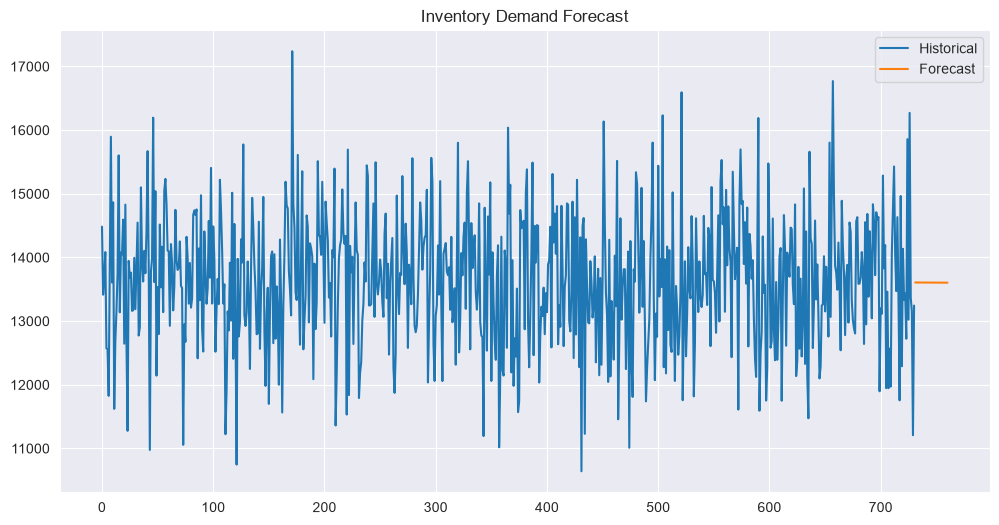

In [9]:
# Visualize Forecast

plt.figure(figsize=(12,6))

plt.plot(
    daily_sales["Day_Number"],
    daily_sales["Units Sold"],
    label="Historical"
)

plt.plot(
    future_days["Day_Number"],
    future_days["Forecast_Units_Sold"],
    label="Forecast"
)

plt.legend()

plt.title(
    "Inventory Demand Forecast"
)

plt.show()

In [10]:
# Stockout Risk Indicator

avg_inventory = (
    df["Inventory Level"].mean()
)

future_days["Stockout_Risk"] = (
    future_days["Forecast_Units_Sold"]
    > avg_inventory
)

future_days.head()

,Day_Number,Forecast_Units_Sold,Stockout_Risk
0,731,13606.942706,True
1,732,13606.834661,True
2,733,13606.726617,True
3,734,13606.618572,True
4,735,13606.510527,True


In [11]:
# Executive Findings

high_risk = (
    future_days[
        future_days["Stockout_Risk"] == True
    ]
)

print(
    f"Forecasted high-risk days: "
    f"{len(high_risk)}"
)


Forecasted high-risk days: 30


In [12]:
# Save Forecast Output

future_days.to_csv(
    "inventory_forecast_output.csv",
    index=False
)

print(
    "Forecast dataset exported."
)

Forecast dataset exported.
